# 04 · Pauli paths: why the campaign's probe returned 0, and where the method works

**The campaign finding.** Early in the campaign (EXP-002B, "Lane Q") the harness asked BlueQubit's `pauli-path`
backend for Pauli-string expectation values on random circuits (RCS). Every job that ran returned **exactly 0.0**;
truncation thresholds ε ≤ 3·10⁻⁵ were refused server-side as a memory risk. At 20 qubits the exact value was
computed locally and was small but non-zero. The lane was dropped and the campaign pivoted to exact-truth MPS
sampling. The README records this as a platform finding.

**Bottom line** (numbers in the sections below): the cloud's exact zeros are what truncated Pauli propagation must
return on this random circuit, and the probed observable could not have told a working approximate method from a
broken one. On a heavy-hex kicked-Ising analogue the same code is accurate after 5 steps and runs out of a laptop's
term budget after 20. A cheap self-check catches the first failure mode, not systematic truncation bias.

**What this notebook does — locally, no API key:**
1. Builds an **independent** Pauli-propagation simulator (`pauli_lite.py`, numpy only, shares no code with the
   campaign or the service) and checks it against exact statevectors.
2. Regenerates the campaign's own 20-qubit probe circuit and observable from their seeds, reproduces the recorded
   exact value, and reproduces the cloud's exact 0 at ε = 10⁻³ and the term explosion behind the refusals at small ε
   (the cloud's 0 at ε = 10⁻⁴ lies beyond our local memory rail).
3. Separates **two different reasons** random circuits defeat the method: the probed observable carried no
   resolvable signal, and even observables that do carry signal lose their operator norm to truncation at depth.
4. Runs the **same code** on a 19-qubit heavy-hex analogue of IBM's kicked-Ising "utility" circuits (Kim et al.,
   *Nature* 618, 500 (2023)), the family that Pauli-path methods were used to simulate classically (Begušić & Chan,
   arXiv:2306.16372; Begušić, Gray & Chan, *Sci. Adv.* 10, eadk4321 (2024)). There it is accurate, until it isn't.
5. Tests whether a loop can **tell the regimes apart without exact truth**, using two cheap self-diagnostics.

Resource note: ≤ 20 qubits, BLAS capped at 2 threads; a run stops as soon as a gate leaves more than 10⁶ Pauli terms
(a local memory rail; the last gate can overshoot it) and is reported as `over_cap`. The notebook runs in a few minutes on a laptop CPU.

**Glossary.** *Lane Q*: the campaign's early attempt to use the `pauli-path` backend for expectation values (dropped).
*`g15b` / `g15c`*: the campaign's pivot screen (EXP-002B) and its expectation-value follow-up; their recorded
outcomes are read from the bundled `runs/20261006T030424Z_g15b/metrics.json`. *ε*: the truncation threshold:
Pauli terms with |coefficient| < ε are dropped after each gate. *retained norm*: the share of the observable's
squared coefficient weight that survives truncation (1 = nothing dropped). *`over_cap`*: a local run stopped at the
10⁶-term rail. *route away*: the gate's verdict "do not trust a Pauli-path answer for this case; send it to another
method".

In [1]:
import os
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "2")
import hashlib, json, re, time
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from qiskit import QuantumCircuit
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import random_unitary, random_statevector, Statevector, SparsePauliOp
from qiskit.transpiler import CouplingMap
import nbcommon as C
import pauli_lite as PL
from mps_lite import gates_from_qiskit

C.style()
B = C.load_bundle()
G15B = B.json("runs/20261006T030424Z_g15b/metrics.json")
T0 = time.time()
CAP = 1_000_000
RAMP = {1e-2: "#86b6ef", 1e-3: "#3987e5", 1e-4: "#1c5cab", 1e-5: "#0d366b"}   # ordinal: smaller ε = darker

# --- verbatim logic of the campaign generators (prototype src/circuits.py::rcs_circuit,
#     src/g15c_ev_semantics.py::random_label)
def rcs_circuit(n_qubits, depth, seed):
    qc = QuantumCircuit(n_qubits, name=f"rcs_n{n_qubits}_d{depth}_s{seed}")
    for d in range(depth):
        for q in range(n_qubits):
            h = int(hashlib.sha256(f"{seed}:{d}:{q}:h".encode()).hexdigest(), 16)
            qc.u((h % 628) / 100.0, ((h >> 10) % 628) / 100.0, ((h >> 20) % 628) / 100.0, q)
        even = d % 2 == 0
        pairs = ([(q, q + 1) for q in range(0, n_qubits - 1, 2)] if even
                 else [(q, q + 1) for q in range(1, n_qubits - 1, 2)])
        for a, b in pairs:
            u = random_unitary(4, seed=(seed * 1_000_003 + d * 1_009 + a * 7 + 1) % (2**31))
            qc.append(UnitaryGate(u.data), [a, b])
    return qc

def random_label(n, weight, seed):
    rng = np.random.default_rng(seed)
    sites = rng.choice(n, size=weight, replace=False)
    chars = rng.choice(list("XYZ"), size=weight)
    label = ["I"] * n
    for s, c in zip(sites, chars):
        label[s] = str(c)
    return "".join(label)

def z_expectations(qc):
    """Exact <Z_q> for every qubit, from qiskit's statevector (independent of pauli_lite)."""
    p = np.abs(np.asarray(Statevector.from_instruction(qc).data)) ** 2
    idx = np.arange(len(p))
    return np.array([np.sum(p * (1 - 2 * ((idx >> q) & 1))) for q in range(qc.num_qubits)])

## 1 · An independent Pauli-path simulator, checked exactly

Heisenberg picture: the observable O = Σ c_s P_s is pulled back through the circuit gate by gate (last gate first),
O → G†OG, using each gate's Pauli transfer matrix. Clifford gates map a Pauli string to one string; generic
gates branch it (a random two-qubit unitary maps a non-identity pair to up to 15). After every gate, equal strings
are merged and terms with |c| < ε are dropped. The estimate is ⟨0…0|O|0…0⟩ = the sum of the coefficients of
strings made only of I and Z. With ε = 0 the method is exact, which is what we check first: random SU(4)
brickwork circuits from the campaign generator, plus a mixed circuit with CX, RZZ and two-qubit unitaries on reversed
qubit pairs (orientation bugs show up there).

In [2]:
checks = []
for n, d, w, s in [(6, 4, 3, 11), (8, 4, 3, 12), (8, 6, 5, 13)]:
    qc = rcs_circuit(n, d, 900 + s)
    lab = random_label(n, w, s)
    ex = float(Statevector.from_instruction(qc).expectation_value(SparsePauliOp(lab)).real)
    r = PL.propagate(gates_from_qiskit(qc), {PL.from_qiskit_label(lab): 1.0}, eps=0.0, max_terms=CAP)
    checks.append((f"RCS n={n} d={d} {lab}", ex, r["ev"], r["terms_peak"]))
mix = QuantumCircuit(5)
mix.h(0); mix.cx(0, 3); mix.append(UnitaryGate(random_unitary(4, seed=3).data), [3, 1]); mix.ry(0.3, 2)
mix.cx(4, 2); mix.append(UnitaryGate(random_unitary(4, seed=4).data), [2, 0]); mix.rzz(0.7, 1, 4); mix.rx(1.1, 3)
sv_mix = Statevector.from_instruction(mix)
for lab in ["ZIIXY", "IYZIX", "ZIIIZ"]:
    ex = float(sv_mix.expectation_value(SparsePauliOp(lab)).real)
    r = PL.propagate(gates_from_qiskit(mix), {PL.from_qiskit_label(lab): 1.0})
    checks.append((f"mixed 5q {lab}", ex, r["ev"], r["terms_peak"]))
max_err_exact = max(abs(a - b) for _, a, b, _ in checks)
display(Markdown("| circuit · observable | exact (statevector) | Pauli path, ε = 0 | peak terms |\n|---|---|---|---|\n" +
                 "\n".join(f"| {c} | {a:+.12f} | {b:+.12f} | {t:,} |" for c, a, b, t in checks)))
print(f"max |difference| over {len(checks)} cases: {max_err_exact:.1e}")
assert max_err_exact < 1e-12

| circuit · observable | exact (statevector) | Pauli path, ε = 0 | peak terms |
|---|---|---|---|
| RCS n=6 d=4 YIIIXZ | -0.001340514407 | -0.001340514407 | 4,065 |
| RCS n=8 d=4 IXIXIIIX | -0.080733686854 | -0.080733686854 | 65,265 |
| RCS n=8 d=6 YIIZXZYI | +0.050977202755 | +0.050977202755 | 65,520 |
| mixed 5q ZIIXY | +0.569110067508 | +0.569110067508 | 450 |
| mixed 5q IYZIX | -0.068255183519 | -0.068255183519 | 345 |
| mixed 5q ZIIIZ | +0.306498923603 | +0.306498923603 | 23 |

max |difference| over 6 cases: 3.3e-16


## 2 · The campaign probe, reproduced locally

The decisive campaign probe (EXP-002B follow-up `g15c`, case A) used a 20-qubit, depth-8 circuit from the campaign
generator (seed 20261300) and a random weight-10 Pauli string (seed 20261301), at four truncation thresholds. The
recorded cloud outcomes are read from the ledger-pinned `metrics.json` in the bundle. We regenerate the circuit and
observable from the seeds, recompute the exact value, and run our own propagation at the same thresholds.

In [3]:
P3 = G15B["probe3_ev_semantics"]
rec_exact = float(re.search(r"vs exact (-?[0-9.]+)", P3["conclusion"]).group(1))
cloud = {}
for row in P3["decisive_rows"] + P3["rejected_rows"]:
    m = re.match(r"g15c-A20-w10-e([0-9.e-]+)$", row["label"])
    if m:
        cloud[float(m.group(1))] = row
probe_qc = rcs_circuit(20, 8, 20261300)
probe_label = random_label(20, 10, 20261301)
probe_exact = float(Statevector.from_instruction(probe_qc).expectation_value(SparsePauliOp(probe_label)).real)
probe_gates = gates_from_qiskit(probe_qc)
probe_obs = {PL.from_qiskit_label(probe_label): 1.0}
print(f"observable (qiskit label, qubit 0 rightmost): {probe_label}")
print(f"exact EV, regenerated here: {probe_exact:+.6f}   recorded by the campaign: {rec_exact:+.6f}")
assert round(probe_exact, 6) == rec_exact

local = {}
for eps in (1e-3, 3e-4, 1e-4, 3e-5, 1e-5):
    local[eps] = PL.propagate(probe_gates, probe_obs, eps=eps, max_terms=CAP, trace=True)

def fmt_cloud(eps):
    r = cloud.get(eps)
    if r is None:
        return "not run"
    if r["status"] == "COMPLETED":
        return f"EV **{r['ev']:.1f}** after {r['wall_min']:.2f} min (`{r['job_id']}`)"
    return f"refused: {r['status']} — memory risk (`{r['job_id']}`)"

def fmt_local(r):
    if r["status"] == "ok":
        return (f"EV **{r['ev']:.1f}**: every term truncated after {r['gates_done']} of {r['gates_total']} gates "
                f"(peak {r['terms_peak']:,} terms, {r['seconds']:.1f} s)" if r["terms_final"] == 0 else
                f"EV {r['ev']:+.6f} ({r['terms_final']:,} terms left)")
    return f"over the 10⁶-term rail after {r['gates_done']} of {r['gates_total']} gates ({r['terms_peak']:,} terms)"

display(Markdown("| ε | cloud `pauli-path` (campaign record) | local `pauli_lite` |\n|---|---|---|\n" +
                 "\n".join(f"| {eps:g} | {fmt_cloud(eps)} | {fmt_local(local[eps])} |" for eps in sorted(local, reverse=True))))

observable (qiskit label, qubit 0 rightmost): IIYIXZIZXXIXIZIZIIIY
exact EV, regenerated here: -0.001112   recorded by the campaign: -0.001112


| ε | cloud `pauli-path` (campaign record) | local `pauli_lite` |
|---|---|---|
| 0.001 | EV **0.0** after 0.04 min (`zFhpsyQvj253UIZG`) | EV **0.0**: every term truncated after 54 of 236 gates (peak 136,508 terms, 0.8 s) |
| 0.0003 | not run | over the 10⁶-term rail after 8 of 236 gates (1,238,521 terms) |
| 0.0001 | EV **0.0** after 4.67 min (`tjiUQT7ynMGEAdix`) | over the 10⁶-term rail after 6 of 236 gates (1,002,635 terms) |
| 3e-05 | refused: FAILED_VALIDATION — memory risk (`dXVuCOcsfDxDfHX0`) | over the 10⁶-term rail after 6 of 236 gates (2,215,478 terms) |
| 1e-05 | refused: FAILED_VALIDATION — memory risk (`28ikE6gaXfTVLS88`) | over the 10⁶-term rail after 6 of 236 gates (3,751,451 terms) |

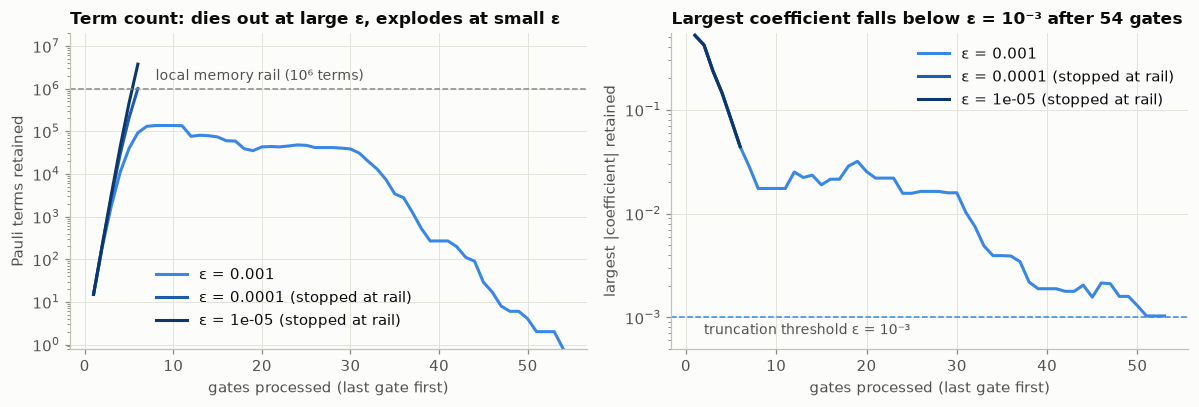

**Reading.** The service's two behaviours are the two ends of one mechanism. Each random two-qubit gate spreads a Pauli string over up to 15 strings while conserving Σc², so coefficients shrink on average. At ε = 10⁻³ the largest surviving coefficient falls below ε after 54 of 236 gates, the retained set becomes empty, and the estimate is **exactly 0.0**: the same number the cloud returned. At smaller ε the strings survive but multiply: our run at ε = 10⁻⁵ passes 10⁶ terms within the first 6 gates, which is the memory risk the service refused at ε ≤ 3·10⁻⁵. (The service completed ε = 10⁻⁴ in 4.7 min and still returned 0.0; our local rail stops that setting earlier, so we do not claim to reproduce its internals, only the two regimes.)

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for eps in (1e-3, 1e-4, 1e-5):
    tr = np.array(local[eps]["trace"])
    x = np.arange(1, len(tr) + 1)
    lab = f"ε = {eps:g}" + ("" if local[eps]["status"] == "ok" else " (stopped at rail)")
    ax[0].plot(x, np.maximum(tr[:, 0], 0.8), color=RAMP[eps], label=lab)
    keep = tr[:, 1] > 0
    ax[1].plot(x[keep], tr[keep, 1], color=RAMP[eps], label=lab)
ax[0].axhline(CAP, color=C.MUTED, ls="--", lw=1)
ax[0].text(8, CAP * 1.6, "local memory rail (10⁶ terms)", color=C.INK_2, fontsize=9)
ax[0].set(yscale="log", ylim=(0.8, 2e7), xlabel="gates processed (last gate first)", ylabel="Pauli terms retained",
          title="Term count: dies out at large ε, explodes at small ε")
ax[1].axhline(1e-3, color=RAMP[1e-3], ls="--", lw=1)
ax[1].text(2, 8.8e-4, "truncation threshold ε = 10⁻³", color=C.INK_2, fontsize=9, va="top")
ax[1].set_ylim(bottom=5e-4)
ax[1].set(yscale="log", xlabel="gates processed (last gate first)", ylabel="largest |coefficient| retained",
          title=f"Largest coefficient falls below ε = 10⁻³ after {local[1e-3]['gates_done']} gates")
ax[0].legend(loc="lower left", bbox_to_anchor=(0.14, 0.02)); ax[1].legend(loc="upper right")
fig.tight_layout(); plt.show()

r3 = local[1e-3]
tr3 = np.array(r3["trace"])
display(Markdown(
    f"**Reading.** The service's two behaviours are the two ends of one mechanism. Each random two-qubit gate spreads a "
    f"Pauli string over up to 15 strings while conserving Σc², so coefficients shrink on average. At ε = 10⁻³ the "
    f"largest surviving coefficient falls below ε after {r3['gates_done']} of {r3['gates_total']} gates, the retained "
    f"set becomes empty, and the estimate is **exactly 0.0**: the same number the cloud returned. At smaller ε the "
    f"strings survive but multiply: our run at ε = 10⁻⁵ passes 10⁶ terms within the first "
    f"{local[1e-5]['gates_done']} gates, which is the memory risk the service refused at ε ≤ 3·10⁻⁵. "
    f"(The service completed ε = 10⁻⁴ in {cloud[1e-4]['wall_min']:.1f} min and still returned 0.0; our local rail "
    f"stops that setting earlier, so we do not claim to reproduce its internals, only the two regimes.)"))

## 3 · Two separate reasons random circuits are the wrong target for this method

**(a) The probed observable carried no resolvable signal.** For a Haar-random n-qubit state, the expectation of any
non-identity Pauli string has mean 0 and variance 1/(2ⁿ + 1) (from the Haar second moment
E|ψᵢ|⁴ = 2/(2ⁿ(2ⁿ+1))). We check that formula by Monte Carlo at 10 qubits and compare the probe's exact value with
the 20-qubit scale. This is a rough reference only: a depth-8 1D circuit is not Haar-random (§3b finds a much
larger value for a low-weight observable on the same circuit). The decisive number is the shot count below.

In [5]:
rng_states = [random_statevector(2**10, seed=s) for s in range(3000)]
zz = SparsePauliOp("ZIIIIIIIXI")
mc = np.array([float(sv.expectation_value(zz).real) for sv in rng_states])
var_formula10 = 1 / (2**10 + 1)
var_mc, var_se = mc.var(), mc.var() * np.sqrt(2 / (len(mc) - 1))
print(f"10 qubits: Monte Carlo variance {var_mc:.3e} ± {var_se:.1e} (3000 Haar states)  vs  1/(2^10+1) = {var_formula10:.3e}")
assert abs(var_mc - var_formula10) < 3 * var_se
haar_sd20 = 1 / np.sqrt(2**20 + 1)
shots_2sigma = (2 / abs(probe_exact)) ** 2
display(Markdown(
    f"At 20 qubits the Haar scale is 1/√(2²⁰+1) = **{haar_sd20:.6f}**; the probe's exact value is "
    f"{probe_exact:+.6f}, i.e. **{abs(probe_exact) / haar_sd20:.2f}×** that scale, indistinguishable from a typical "
    f"scrambled value. Resolving its sign at 2σ from ±1 single-shot outcomes would take ≈ (2/|EV|)² = "
    f"**{shots_2sigma / 1e6:.1f} million shots** even on a perfect device. Any estimator that returns 0 is within "
    f"{abs(probe_exact):.4f} of the truth, so on this observable a returned 0 tells us nothing about any method."))

10 qubits: Monte Carlo variance 9.968e-04 ± 2.6e-05 (3000 Haar states)  vs  1/(2^10+1) = 9.756e-04


At 20 qubits the Haar scale is 1/√(2²⁰+1) = **0.000977**; the probe's exact value is -0.001112, i.e. **1.14×** that scale, indistinguishable from a typical scrambled value. Resolving its sign at 2σ from ±1 single-shot outcomes would take ≈ (2/|EV|)² = **3.2 million shots** even on a perfect device. Any estimator that returns 0 is within 0.0011 of the truth, so on this observable a returned 0 tells us nothing about any method.

**(b) Observables that do carry signal lose their operator norm to truncation.** A single-qubit Z in the middle of
the same 20-qubit circuit keeps a sizeable exact value at depth 8: brickwork scrambles local observables slowly.
We sweep the circuit depth (the depth-d circuit is the first d layers of the probe circuit) and compare the
truncated estimate with the exact value. We also track the **retained norm** Σc² / Σc²₀: it is exactly
conserved without truncation, so it measures how much of the observable truncation threw away.

depth sweep done (41s since start)


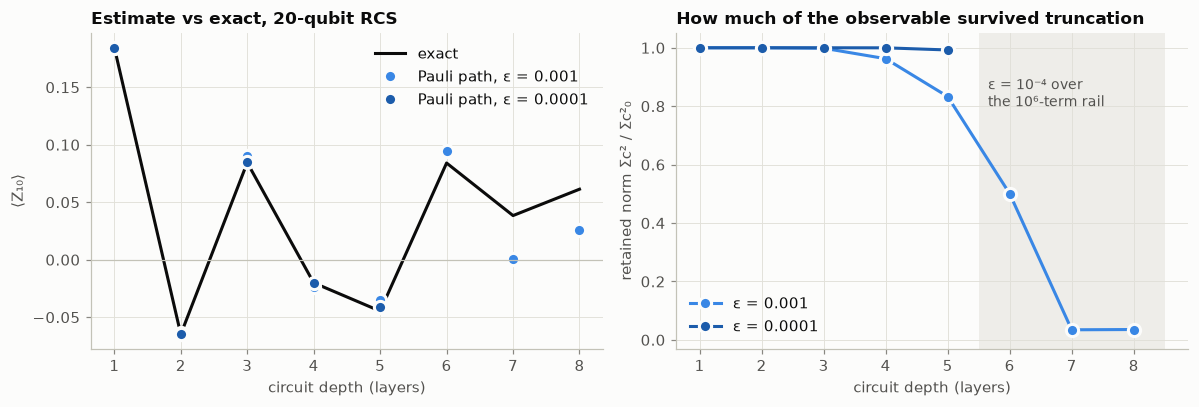

**Reading.** With ε = 10⁻⁴ the estimate tracks the exact value up to depth 5 (max |error| 0.0038); beyond that the term count passes the local rail. At ε = 10⁻³ the retained norm falls to **0.035** at depth 8 and the estimate (+0.0257) misses the exact +0.0613, which is well above the Haar scale. Here the method fails on a quantity that does exist. Random circuits are built to make operator spreading maximal, so this is the expected regime, not a platform defect.

In [6]:
rcs_rows = []
for d in range(1, 9):
    qc = rcs_circuit(20, d, 20261300)
    ex = float(z_expectations(qc)[10])
    G = gates_from_qiskit(qc)
    for eps in (1e-3, 1e-4):
        r = PL.propagate(G, {PL.pauli_string({10: "Z"}): 1.0}, eps=eps, max_terms=CAP)
        rcs_rows.append({"family": "RCS 20q", "x": d, "eps": eps, "exact": ex, **r})
print(f"depth sweep done ({time.time() - T0:.0f}s since start)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ds = np.arange(1, 9)
ax[0].plot(ds, [next(r["exact"] for r in rcs_rows if r["x"] == d) for d in ds], color=C.INK, lw=2, label="exact")
for eps in (1e-3, 1e-4):
    rr = [r for r in rcs_rows if r["eps"] == eps and r["status"] == "ok"]
    ax[0].plot([r["x"] for r in rr], [r["ev"] for r in rr], "o", ms=8, color=RAMP[eps], mec=C.SURFACE, mew=2,
               label=f"Pauli path, ε = {eps:g}")
    ax[1].plot([r["x"] for r in rr], [r["norm_retained"] for r in rr], "o-", ms=8, color=RAMP[eps], mec=C.SURFACE,
               mew=2, label=f"ε = {eps:g}")
over = [r["x"] for r in rcs_rows if r["eps"] == 1e-4 and r["status"] != "ok"]
if over:
    ax[1].axvspan(min(over) - 0.5, 8.5, color=C.GRID, alpha=0.5, lw=0)
    ax[1].text(min(over) - 0.35, 0.80, "ε = 10⁻⁴ over\nthe 10⁶-term rail", color=C.INK_2, fontsize=9)
ax[0].axhline(0, color=C.AXIS, lw=0.8)
ax[0].set(xlabel="circuit depth (layers)", ylabel="⟨Z₁₀⟩", title="Estimate vs exact, 20-qubit RCS")
ax[1].set(xlabel="circuit depth (layers)", ylabel="retained norm Σc² / Σc²₀", ylim=(-0.03, 1.05),
          title="How much of the observable survived truncation")
ax[0].legend(loc="upper right"); ax[1].legend(loc="lower left")
fig.tight_layout(); plt.show()

ok4 = [r for r in rcs_rows if r["eps"] == 1e-4 and r["status"] == "ok"]
last_ok = max(r["x"] for r in ok4)
d8 = next(r for r in rcs_rows if r["x"] == 8 and r["eps"] == 1e-3)
display(Markdown(
    f"**Reading.** With ε = 10⁻⁴ the estimate tracks the exact value up to depth {last_ok} "
    f"(max |error| {max(abs(r['ev'] - r['exact']) for r in ok4):.4f}); beyond that the term count passes the local "
    f"rail. At ε = 10⁻³ the retained norm falls to **{d8['norm_retained']:.3f}** at depth 8 and the estimate "
    f"({d8['ev']:+.4f}) misses the exact {d8['exact']:+.4f}, which is well above the Haar scale. Here the method fails "
    f"on a quantity that does exist. Random circuits are built to make operator spreading maximal, so this is "
    f"the expected regime, not a platform defect."))

## 4 · Same code, structured circuit: kicked Ising on a heavy-hex patch

IBM's 127-qubit utility experiment (Kim et al. 2023) ran Trotterized kicked-Ising circuits on a heavy-hex device:
per step, RX(θ_h) on every qubit, then RZZ(−π/2) on every coupled pair, starting from |0…0⟩. The ZZ part is
Clifford, so Pauli strings branch only at the RX gates, and not at all at θ_h = 0 or π/2. We use the 19-qubit
heavy-hex patch from qiskit's `CouplingMap.from_heavy_hex(3)` and two analogues of the paper's observables:
the mean magnetization M_z after 5 steps over a θ_h sweep (their Fig. 3 regime), and a single central ⟨Z⟩ after
20 steps (their Fig. 4b regime). At 19 qubits both are checked against the exact statevector.

heavy-hex patch: 19 qubits, 20 couplers, degree counts {1: 2, 2: 13, 3: 4}; central qubit 15 (eccentricity 5)


kicked-Ising sweeps done (108s since start)


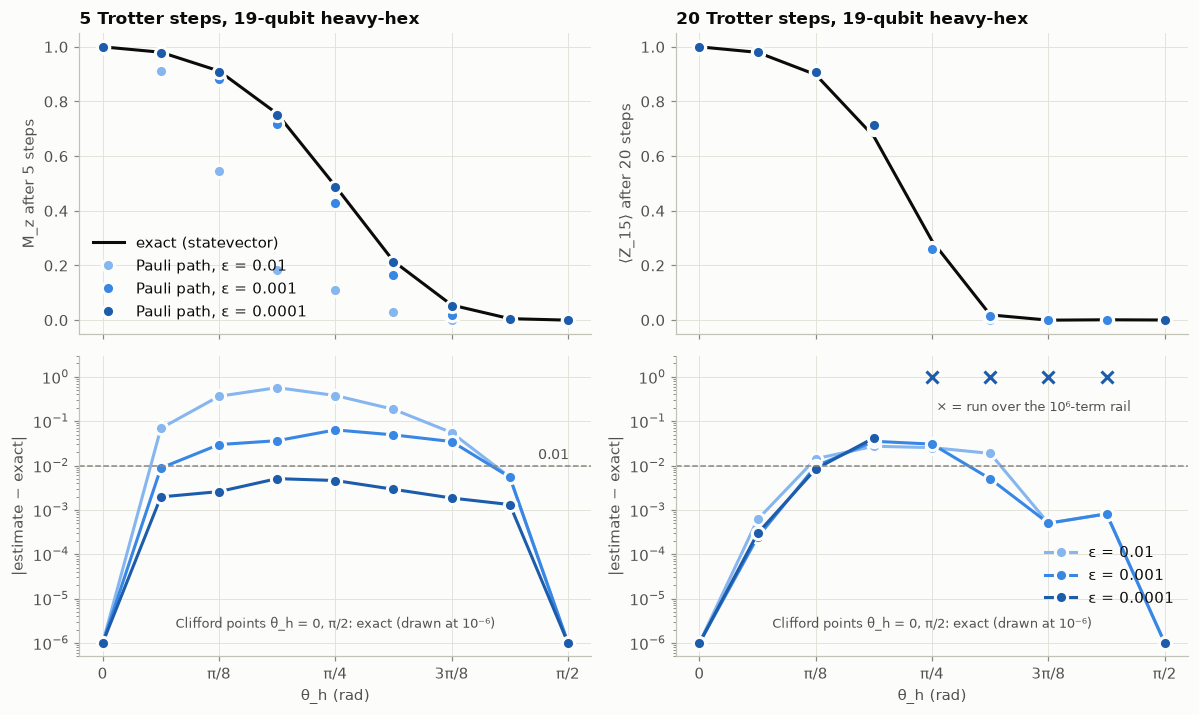

**Reading.** After 5 steps, ε = 10⁻⁴ reproduces M_z at all 9 angles with max |error| **0.0051** (worst at θ_h = 3π/16 ≈ 0.589), never holding more than 175,418 terms, at most 0.3 s per angle. This is the 5-step regime of IBM's θ_h sweep. After 20 steps the laptop budget no longer suffices: ε = 10⁻⁴ exceeds the 10⁶-term rail at 4 of 9 angles, and where it completes the error reaches 0.0421 (θ_h = 3π/16 ≈ 0.589; ε = 10⁻³: 0.0352 over 9 completed angles). Begušić & Chan also treated IBM's 20-step case at 127 qubits, with far larger term budgets, so the binding limit here is our rail, not the method. At the Clifford end points the method is exact with at most 19 terms. The zeros on random circuits are not a defect of the method: it is a tool with a regime, set by how far the circuit's operator spreading is from Clifford-like.

In [7]:
cm = CouplingMap.from_heavy_hex(3)
HH_N = cm.size()
HH_EDGES = sorted({tuple(sorted(e)) for e in cm.get_edges()})
deg = np.bincount(np.array(HH_EDGES).ravel(), minlength=HH_N)
dist = np.asarray(cm.distance_matrix)
center = int(min((q for q in range(HH_N) if deg[q] == 3), key=lambda q: dist[q].max()))
print(f"heavy-hex patch: {HH_N} qubits, {len(HH_EDGES)} couplers, degree counts {{{', '.join(f'{int(k)}: {int(v)}' for k, v in zip(*np.unique(deg, return_counts=True)))}}}; "
      f"central qubit {center} (eccentricity {int(dist[center].max())})")

def kicked_ising(theta, steps):
    qc = QuantumCircuit(HH_N)
    for _ in range(steps):
        for q in range(HH_N):
            qc.rx(theta, q)
        for a, b in HH_EDGES:
            qc.rzz(-np.pi / 2, a, b)
    return qc

THETAS = np.linspace(0, np.pi / 2, 9)
def fmt_th(x, approx=True):
    """θ_h as a multiple of π/16 (the grid spacing), e.g. '3π/16 ≈ 0.589'."""
    k = x / (np.pi / 16)
    if abs(k - round(k)) > 1e-9:
        return f"{x:.3f}"
    k = round(k)
    if k == 0:
        return "0"
    f = Fraction(k, 16)
    lab = ("" if f.numerator == 1 else str(f.numerator)) + "π" + ("" if f.denominator == 1 else f"/{f.denominator}")
    return f"{lab} ≈ {x:.3f}" if approx else lab
ki_rows = []
for th in THETAS:
    qc5, qc20 = kicked_ising(th, 5), kicked_ising(th, 20)
    mz5 = float(np.mean(z_expectations(qc5)))
    zc20 = float(z_expectations(qc20)[center])
    g5, g20 = gates_from_qiskit(qc5), gates_from_qiskit(qc20)
    for eps in (1e-2, 1e-3, 1e-4):
        r = PL.propagate(g5, {PL.pauli_string({q: "Z"}): 1 / HH_N for q in range(HH_N)}, eps=eps, max_terms=CAP)
        ki_rows.append({"family": "kicked Ising, 5 steps, M_z", "x": th, "eps": eps, "exact": mz5, **r})
        r = PL.propagate(g20, {PL.pauli_string({center: "Z"}): 1.0}, eps=eps, max_terms=CAP)
        ki_rows.append({"family": f"kicked Ising, 20 steps, Z_{center}", "x": th, "eps": eps, "exact": zc20, **r})
print(f"kicked-Ising sweeps done ({time.time() - T0:.0f}s since start)")

FAM5, FAM20 = "kicked Ising, 5 steps, M_z", f"kicked Ising, 20 steps, Z_{center}"
FLOOR = 1e-6
fig, ax = plt.subplots(2, 2, figsize=(11, 6.6), sharex=True)
for j, (fam, ylab) in enumerate([(FAM5, "M_z after 5 steps"), (FAM20, f"⟨Z_{center}⟩ after 20 steps")]):
    rr = [r for r in ki_rows if r["family"] == fam]
    ex = [next(r["exact"] for r in rr if r["x"] == th) for th in THETAS]
    ax[0, j].plot(THETAS, ex, color=C.INK, lw=2, label="exact (statevector)")
    for eps in (1e-2, 1e-3, 1e-4):
        e = [r for r in rr if r["eps"] == eps and r["status"] == "ok"]
        ax[0, j].plot([r["x"] for r in e], [r["ev"] for r in e], "o", ms=8, color=RAMP[eps], mec=C.SURFACE, mew=2,
                      label=f"Pauli path, ε = {eps:g}")
        allr = sorted((r for r in rr if r["eps"] == eps), key=lambda r: r["x"])
        err = [max(abs(r["ev"] - r["exact"]), FLOOR) if r["status"] == "ok" else np.nan for r in allr]
        ax[1, j].plot([r["x"] for r in allr], err, "o-", ms=8, color=RAMP[eps], mec=C.SURFACE, mew=2,
                      label=f"ε = {eps:g}")
        oc = [r["x"] for r in allr if r["status"] != "ok"]
        if oc:
            ax[1, j].plot(oc, [1.0] * len(oc), "x", ms=8, mew=2, color=RAMP[eps])
    ax[0, j].set(ylabel=ylab, title=f"{'5' if fam == FAM5 else '20'} Trotter steps, 19-qubit heavy-hex")
    ax[1, j].axhline(1e-2, color=C.MUTED, ls="--", lw=1)
    ax[1, j].set(yscale="log", ylim=(FLOOR / 2, 3), ylabel="|estimate − exact|", xlabel="θ_h (rad)")
    ax[1, j].text(np.pi / 4, 2.2 * FLOOR, "Clifford points θ_h = 0, π/2: exact (drawn at 10⁻⁶)", color=C.INK_2,
                  fontsize=8.5, ha="center")
    ax[1, j].set_xticks([0, np.pi / 8, np.pi / 4, 3 * np.pi / 8, np.pi / 2], ["0", "π/8", "π/4", "3π/8", "π/2"])
ax[1, 0].text(1.47, 1.4e-2, "0.01", color=C.INK_2, fontsize=9)
ax[1, 1].text(0.8, 0.3, "× = run over the 10⁶-term rail", color=C.INK_2, fontsize=8.5, va="top")
ax[0, 0].legend(loc="lower left"); ax[1, 1].legend(loc="lower right", bbox_to_anchor=(1, 0.12))
fig.tight_layout(); plt.show()

def n_over(fam, eps):
    return sum(r["status"] != "ok" for r in ki_rows if r["family"] == fam and r["eps"] == eps)

def worst(fam, eps):
    e = [r for r in ki_rows if r["family"] == fam and r["eps"] == eps and r["status"] == "ok"]
    w = max(e, key=lambda r: abs(r["ev"] - r["exact"]))
    return abs(w["ev"] - w["exact"]), w["x"], max(r["terms_peak"] for r in e), max(r["seconds"] for r in e), len(e)

w5, w20 = worst(FAM5, 1e-4), worst(FAM20, 1e-4)
w20b = worst(FAM20, 1e-3)
cliff_peak = max(r["terms_peak"] for r in ki_rows if r["x"] in (THETAS[0], THETAS[-1]))
display(Markdown(
    f"**Reading.** After 5 steps, ε = 10⁻⁴ reproduces M_z at all {w5[4]} angles with max |error| **{w5[0]:.4f}** "
    f"(worst at θ_h = {fmt_th(w5[1])}), never holding more than {w5[2]:,} terms, at most {w5[3]:.1f} s per angle. This is "
    f"the 5-step regime of IBM's θ_h sweep. After 20 steps the laptop budget no longer suffices: ε = 10⁻⁴ exceeds the "
    f"10⁶-term rail at {n_over(FAM20, 1e-4)} of {n_over(FAM20, 1e-4) + w20[4]} angles, and where it completes the error "
    f"reaches {w20[0]:.4f} (θ_h = {fmt_th(w20[1])}; ε = 10⁻³: {w20b[0]:.4f} over {w20b[4]} completed angles). Begušić & Chan "
    f"also treated IBM's 20-step case at 127 qubits, with far larger term budgets, so the binding limit here is our "
    f"rail, not the method. At the Clifford end points the method is exact with at most {cliff_peak} terms. The zeros on "
    f"random circuits are not a defect of the method: it is a tool with a regime, set by how far the circuit's operator "
    f"spreading is from Clifford-like."))

## 5 · Can an automated loop tell the regimes apart without exact truth?

At verification scale we have exact answers; at attack scale we will not. Two signals are free to compute:

- **ε-convergence**: |EV(ε) − EV(ε/10)|, an *estimate* of the error of EV(ε) (standard practice: refine until the
  value stops moving). If the finer run hits the memory rail, the estimate is *unresolved*.
- **retained norm** of the finer run, a degeneracy flag: near 0 means the estimate rests on almost nothing.

The panel compares the ε-convergence estimate for EV(10⁻³) with its true error over every run in sections 3–4
(and the probe from section 2). The rule in the second cell was written for this notebook after seeing these
runs. It illustrates the gate design; it has not been validated.

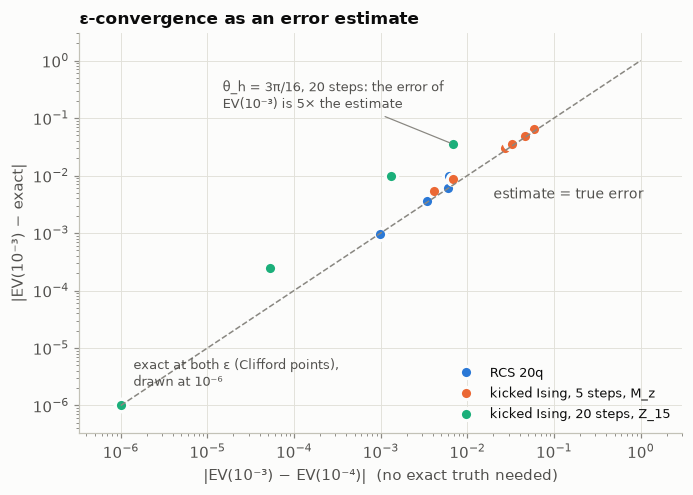

27 cases; 19 resolved; 8 unresolved (finer run over the rail): RCS 20q @ 6, RCS 20q @ 7, RCS 20q @ 8, kicked Ising, 20 steps, Z_15 @ π/4 ≈ 0.785, kicked Ising, 20 steps, Z_15 @ 5π/16 ≈ 0.982, kicked Ising, 20 steps, Z_15 @ 3π/8 ≈ 1.178, kicked Ising, 20 steps, Z_15 @ 7π/16 ≈ 1.374, RCS 20q, weight-10 probe @ 8


In [8]:
by = {}
for r in rcs_rows + ki_rows:
    by.setdefault((r["family"], r["x"]), {})[r["eps"]] = r
by[("RCS 20q, weight-10 probe", 8)] = {1e-3: {**local[1e-3], "exact": probe_exact}, 1e-4: {**local[1e-4], "exact": probe_exact}}
pairs = []
for (fam, x), runs in by.items():
    a, b = runs[1e-3], runs[1e-4]
    resolved = a["status"] == "ok" and b["status"] == "ok"
    pairs.append({"family": fam, "x": x, "true_err": abs(a["ev"] - a["exact"]) if a["status"] == "ok" else np.nan,
                  "est_err": abs(a["ev"] - b["ev"]) if resolved else np.nan, "resolved": resolved,
                  "norm_fine": b["norm_retained"] if resolved else np.nan, "fine_true_err": abs(b["ev"] - b["exact"]) if resolved else np.nan})

FAM_COLOR = {"RCS 20q": C.BLUE, FAM5: C.ORANGE, FAM20: C.AQUA, "RCS 20q, weight-10 probe": C.NEUTRAL}
fig, ax = plt.subplots(figsize=(6.4, 4.6))
lo = FLOOR
for fam, col in FAM_COLOR.items():
    pp = [p for p in pairs if p["family"] == fam and p["resolved"]]
    if pp:
        ax.plot([max(p["est_err"], lo) for p in pp], [max(p["true_err"], lo) for p in pp], "o", ms=8, color=col,
                mec=C.SURFACE, mew=2, label=fam)
ax.plot([lo, 1], [lo, 1], color=C.MUTED, ls="--", lw=1)
ax.text(2e-2, 4e-3, "estimate = true error", color=C.INK_2, fontsize=9, ha="left")
ax.text(1.4 * lo, 2.2 * lo, "exact at both ε (Clifford points),\ndrawn at 10⁻⁶", color=C.INK_2, fontsize=8.5)
under = max((p for p in pairs if p["resolved"] and p["true_err"] > 0.01), key=lambda p: p["true_err"] / max(p["est_err"], lo))
ax.annotate(f"θ_h = {fmt_th(under['x'], approx=False)}, 20 steps: the error of\nEV(10⁻³) is {under['true_err'] / under['est_err']:.0f}× the estimate",
            (under["est_err"], under["true_err"]), xytext=(1.5e-5, 1.5e-1), color=C.INK_2, fontsize=8.5,
            arrowprops=dict(arrowstyle="-", color=C.MUTED, lw=0.8))
ax.set(xscale="log", yscale="log", xlim=(lo / 3, 3), ylim=(lo / 3, 3), xlabel="|EV(10⁻³) − EV(10⁻⁴)|  (no exact truth needed)",
       ylabel="|EV(10⁻³) − exact|", title="ε-convergence as an error estimate")
ax.legend(loc="lower right", fontsize=8.5)
fig.tight_layout(); plt.show()
n_unres = sum(not p["resolved"] for p in pairs)
print(f"{len(pairs)} cases; {len(pairs) - n_unres} resolved; {n_unres} unresolved (finer run over the rail): "
      + ", ".join(f"{p['family']} @ {p['x'] if isinstance(p['x'], int) else fmt_th(p['x'])}" for p in pairs if not p["resolved"]))

In [9]:
TAU, NORM_MIN = 0.01, 0.5
def decide(p):
    if not p["resolved"]:
        return "route away (unresolved)"
    if p["norm_fine"] < NORM_MIN:
        return "route away (degenerate)"
    return "accept EV(10⁻⁴)" if p["est_err"] <= TAU else "refine / route away"
for p in pairs:
    p["decision"] = decide(p)
acc = [p for p in pairs if p["decision"].startswith("accept")]
rej = [p for p in pairs if not p["decision"].startswith("accept")]
false_acc = [p for p in acc if p["fine_true_err"] > TAU]
missed_ok = [p for p in rej if p["resolved"] and p["fine_true_err"] <= TAU]
def max_err_str(fam):
    e = [p["fine_true_err"] for p in acc if p["family"] == fam]
    return f"{max(e):.4f}" if e else "—"
display(Markdown(
    f"**Illustrative gate** (accept EV(10⁻⁴) only if resolved, retained norm ≥ {NORM_MIN} and "
    f"|EV(10⁻³) − EV(10⁻⁴)| ≤ {TAU}):\n\n"
    f"| family | cases | accepted | max true error of accepted EV(10⁻⁴) | routed away / refine |\n|---|---|---|---|---|\n" +
    "\n".join(f"| {fam} | {sum(p['family'] == fam for p in pairs)} | {sum(p['family'] == fam for p in acc)} | "
              f"{max_err_str(fam)} | "
              f"{sum(p['family'] == fam for p in rej)} |" for fam in FAM_COLOR) +
    f"\n\nThe rule accepts {len(acc)} of {len(pairs)} cases and routes the campaign probe away "
    f"(*{next(p['decision'] for p in pairs if p['family'].endswith('probe'))}*). It is conservative on "
    f"{len(missed_ok)} resolved cases whose EV(10⁻⁴) was in fact within {TAU} (refining further would settle them). "
    f"It also makes **{len(false_acc)} false acceptance{'s' if len(false_acc) != 1 else ''}**:"))
for p in false_acc:
    runs = by[(p["family"], p["x"])]
    traj = ", ".join(f"ε = {e:g}: {runs[e]['ev']:+.4f}" for e in sorted(runs, reverse=True) if runs[e]["status"] == "ok")
    display(Markdown(
        f"- {p['family']}, θ_h = {fmt_th(p['x'])}: exact {runs[1e-4]['exact']:+.4f}; estimates {traj}; retained norm at "
        f"ε = 10⁻⁴ {p['norm_fine']:.3f}. As ε shrinks the estimate moves *away* from the exact value while successive "
        f"thresholds agree to {p['est_err']:.4f}. The truncation bias is systematic, and a one-decade convergence "
        f"check cannot see it."))

**Illustrative gate** (accept EV(10⁻⁴) only if resolved, retained norm ≥ 0.5 and |EV(10⁻³) − EV(10⁻⁴)| ≤ 0.01):

| family | cases | accepted | max true error of accepted EV(10⁻⁴) | routed away / refine |
|---|---|---|---|---|
| RCS 20q | 8 | 5 | 0.0038 | 3 |
| kicked Ising, 5 steps, M_z | 9 | 4 | 0.0020 | 5 |
| kicked Ising, 20 steps, Z_15 | 9 | 5 | 0.0421 | 4 |
| RCS 20q, weight-10 probe | 1 | 0 | — | 1 |

The rule accepts 14 of 27 cases and routes the campaign probe away (*route away (unresolved)*). It is conservative on 5 resolved cases whose EV(10⁻⁴) was in fact within 0.01 (refining further would settle them). It also makes **1 false acceptance**:

- kicked Ising, 20 steps, Z_15, θ_h = 3π/16 ≈ 0.589: exact +0.6717; estimates ε = 0.01: +0.6990, ε = 0.001: +0.7070, ε = 0.0001: +0.7138; retained norm at ε = 10⁻⁴ 0.887. As ε shrinks the estimate moves *away* from the exact value while successive thresholds agree to 0.0068. The truncation bias is systematic, and a one-decade convergence check cannot see it.

## 6 · What this changes in the scaled-up loop

In [10]:
display(Markdown(f"""
- **The campaign was right to drop Lane Q, for a reason the probe alone could not show.** The
  `pauli-path` zeros are the expected output of coefficient truncation on a random circuit. The probed weight-10
  observable's exact value ({probe_exact:+.6f}) sits at the Haar scale ({haar_sd20:.6f}); resolving it would take
  ≈ {shots_2sigma / 1e6:.1f} M shots even on a perfect device. It was not a usable target for testing an approximate
  method: returning 0 already achieves absolute error {abs(probe_exact):.4f}, so a returned 0 cannot tell a working
  estimator from a broken one.
- **Pauli paths are a regime tool, so the attack portfolio routes by regime.** On the heavy-hex kicked-Ising analogue
  the same code is accurate to {w5[0]:.4f} after 5 steps in seconds; after 20 steps it exceeds the laptop budget at
  {n_over(FAM20, 1e-4)} of {n_over(FAM20, 1e-4) + w20[4]} angles and errs by up to {w20[0]:.4f} elsewhere. On 20-qubit random circuits it fails beyond
  depth {last_ok} at the thresholds a laptop can hold. The scaled loop sends observable-estimation claims on
  near-Clifford/structured circuits (utility-type experiments) to Pauli paths, and sampling claims to tensor networks
  and MPS, as in notebook 03.
- **Cheap self-checks are useful but not sufficient.** ε-convergence plus a retained-norm floor accepted
  {len(acc)} of {len(pairs)} cases ({sum(p['family'].startswith('kicked') and p['x'] in (THETAS[0], THETAS[-1]) for p in acc)} of them trivial Clifford points) and refused the campaign probe, but also made {len(false_acc)} false
  acceptance{'s' if len(false_acc) != 1 else ''} (true error {max([p['fine_true_err'] for p in false_acc], default=0):.4f}),
  where truncation bias was systematic. So the
  scale-up gate for Pauli-path verdicts is preregistered and **calibrated against exact answers on verifiable
  instances** (large-core CPU runs at the largest exactly checkable sizes), and its measured false-accept rate is
  published with every verdict. That is the same "verify at checkable scale" rule the campaign used for sampling,
  and it is what notebook 02 asks of the promotion gate.
- **Noise is a mutation axis, not only a nuisance.** Noise damps high-weight Pauli strings, and that is the
  mechanism behind polynomial-time Pauli-path algorithms for noisy random circuits (Aharonov, Gao, Landau, Liu &
  Vazirani, arXiv:2211.03999, STOC 2023) and for noisy circuits generally (Schuster, Yin, Gao & Yao,
  arXiv:2407.12768, *PRX* 15, 041018 (2025)). Attacks on hardware claims should include device-calibrated noise
  in the classical model. That is one use of the requested IBM shots. Not tested in this notebook.
"""))


- **The campaign was right to drop Lane Q, for a reason the probe alone could not show.** The
  `pauli-path` zeros are the expected output of coefficient truncation on a random circuit. The probed weight-10
  observable's exact value (-0.001112) sits at the Haar scale (0.000977); resolving it would take
  ≈ 3.2 M shots even on a perfect device. It was not a usable target for testing an approximate
  method: returning 0 already achieves absolute error 0.0011, so a returned 0 cannot tell a working
  estimator from a broken one.
- **Pauli paths are a regime tool, so the attack portfolio routes by regime.** On the heavy-hex kicked-Ising analogue
  the same code is accurate to 0.0051 after 5 steps in seconds; after 20 steps it exceeds the laptop budget at
  4 of 9 angles and errs by up to 0.0421 elsewhere. On 20-qubit random circuits it fails beyond
  depth 5 at the thresholds a laptop can hold. The scaled loop sends observable-estimation claims on
  near-Clifford/structured circuits (utility-type experiments) to Pauli paths, and sampling claims to tensor networks
  and MPS, as in notebook 03.
- **Cheap self-checks are useful but not sufficient.** ε-convergence plus a retained-norm floor accepted
  14 of 27 cases (4 of them trivial Clifford points) and refused the campaign probe, but also made 1 false
  acceptance (true error 0.0421),
  where truncation bias was systematic. So the
  scale-up gate for Pauli-path verdicts is preregistered and **calibrated against exact answers on verifiable
  instances** (large-core CPU runs at the largest exactly checkable sizes), and its measured false-accept rate is
  published with every verdict. That is the same "verify at checkable scale" rule the campaign used for sampling,
  and it is what notebook 02 asks of the promotion gate.
- **Noise is a mutation axis, not only a nuisance.** Noise damps high-weight Pauli strings, and that is the
  mechanism behind polynomial-time Pauli-path algorithms for noisy random circuits (Aharonov, Gao, Landau, Liu &
  Vazirani, arXiv:2211.03999, STOC 2023) and for noisy circuits generally (Schuster, Yin, Gao & Yao,
  arXiv:2407.12768, *PRX* 15, 041018 (2025)). Attacks on hardware claims should include device-calibrated noise
  in the classical model. That is one use of the requested IBM shots. Not tested in this notebook.


## Checks

In [11]:
final_checks = [
    ("Pauli path at ε = 0 equals exact statevector (6 circuits/observables)", max_err_exact < 1e-12),
    ("regenerated probe exact EV == campaign record (6 decimals)", round(probe_exact, 6) == rec_exact),
    ("local ε = 1e-3 returns exactly 0.0 with an empty retained set (as the cloud did)",
     local[1e-3]["status"] == "ok" and local[1e-3]["ev"] == 0.0 and local[1e-3]["terms_final"] == 0
     and cloud[1e-3]["ev"] == 0.0),
    ("local ε ≤ 1e-4 all exceed the 10⁶-term rail (the local rail is tighter than the service's; cloud refused ε ≤ 3e-5)",
     all(local[e]["status"] == "over_cap" for e in (1e-4, 3e-5, 1e-5))
     and all(cloud[e]["status"] == "FAILED_VALIDATION" for e in (3e-5, 1e-5))),
    ("Haar variance formula confirmed by Monte Carlo at 10 qubits", abs(var_mc - var_formula10) < 3 * var_se),
    ("probe |EV| within 2 Haar standard deviations at 20 qubits", abs(probe_exact) < 2 * haar_sd20),
    ("kicked Ising 5 steps: ε = 1e-4 max |error| < 0.01 at every angle", w5[0] < 0.01 and w5[4] == len(THETAS)),
    ("Clifford end points (θ_h = 0, π/2) exact for every ε",
     all(abs(r["ev"] - r["exact"]) < 1e-9 for r in ki_rows if r["x"] in (THETAS[0], THETAS[-1]))),
]
for name, ok in final_checks:
    print(("PASS  " if ok else "FAIL  ") + name)
print(f"\n{sum(ok for _, ok in final_checks)}/{len(final_checks)} checks pass · total runtime {time.time() - T0:.0f}s")
assert all(ok for _, ok in final_checks)

PASS  Pauli path at ε = 0 equals exact statevector (6 circuits/observables)
PASS  regenerated probe exact EV == campaign record (6 decimals)
PASS  local ε = 1e-3 returns exactly 0.0 with an empty retained set (as the cloud did)
PASS  local ε ≤ 1e-4 all exceed the 10⁶-term rail (the local rail is tighter than the service's; cloud refused ε ≤ 3e-5)
PASS  Haar variance formula confirmed by Monte Carlo at 10 qubits
PASS  probe |EV| within 2 Haar standard deviations at 20 qubits
PASS  kicked Ising 5 steps: ε = 1e-4 max |error| < 0.01 at every angle
PASS  Clifford end points (θ_h = 0, π/2) exact for every ε

8/8 checks pass · total runtime 109s
